# Encoders v1: UNI vs CONCH on pt109

Trial run of the pathology encoders on the only labeled sample slide (pt109), using the tumor and benign tiles from `tiles_v1`.

**What this can and cannot show.** With one slide, nothing here measures how well a model generalizes to new patients.
It checks that the pipeline runs end to end, and compares the two encoders on the same tiles:

1. Extract tile features with UNI and CONCH.
2. Look at the features (PCA): do tumor and benign tiles separate?
3. Linear probe: a simple classifier on top of each encoder, tested on parts of the slide it did not train on (spatial cross-validation).
4. CONCH zero-shot: score tiles against text such as "prostate adenocarcinoma", with no training at all.
5. Paint the predictions back onto the slide.

Tumor labels are rough (ink regions include stroma), so perfect scores are not expected.

**Before running**
* Hugging Face access approved for **MahmoodLab/UNI** and **MahmoodLab/conch**, and a token saved as a Colab secret `HF_TOKEN`.
* GPU runtime (Runtime > Change runtime type > T4 GPU).
* Run the install cell, restart the session, then run from the mount cell.

## 0. Install, then restart the session

In [2]:
!pip install -q "imagecodecs[all]" tifffile timm
!pip install -q git+https://github.com/Mahmoodlab/CONCH.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not in Colab; skipping Drive mount.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Setup and tile selection

In [4]:
import os, time, threading
import numpy as np
import pandas as pd
import tifffile, imagecodecs
import matplotlib.pyplot as plt
from PIL import Image
from functools import lru_cache
from concurrent.futures import ThreadPoolExecutor
from IPython.display import display

DATA_DIR  = '/content/drive/MyDrive/spring/capstone/data'
TILES_CSV = os.path.join(DATA_DIR, 'tiles_v1', 'pt109_tile_labels.csv')
SLIDE     = os.path.join(DATA_DIR, 'pt109.ome.tif')
OUT_DIR   = os.path.join(DATA_DIR, 'encoders_v1')
os.makedirs(os.path.join(OUT_DIR, 'figures'), exist_ok=True)
assert os.path.exists(TILES_CSV), 'Run the tiles_v1 notebook first'

N_BENIGN    = 5000   # benign tiles to sample (all 579 tumor tiles are used); None = all ~26.5k, about 5x slower
SEED        = 0
BATCH       = 64
N_THREADS   = 8
BLOCK_TILES = 16     # spatial cross-validation block: 16 tiles = about 2 mm

def save_fig(name):
    plt.savefig(os.path.join(OUT_DIR, 'figures', f'{name}.png'), dpi=150, bbox_inches='tight')

t = pd.read_csv(TILES_CSV)
tumor  = t[t.label == 'tumor']
benign = t[t.label == 'benign_presumed']
if N_BENIGN is not None and len(benign) > N_BENIGN:
    benign = benign.sample(N_BENIGN, random_state=SEED)
tiles = pd.concat([tumor, benign]).sort_values(['y0', 'x0']).reset_index(drop=True)
tiles['y'] = (tiles.label == 'tumor').astype(int)
tiles['block'] = (tiles.gy // BLOCK_TILES).astype(str) + '_' + (tiles.gx // BLOCK_TILES).astype(str)
print(f'{len(tiles)} tiles: {tiles.y.sum()} tumor, {(1 - tiles.y).sum()} benign, {tiles.block.nunique()} spatial blocks')

5579 tiles: 579 tumor, 5000 benign, 138 spatial blocks


## 2. Slide reader (same as tiles_v1)

In [5]:
def to_rgb(arr):
    arr = np.squeeze(arr)
    if arr.ndim == 2: arr = np.stack([arr] * 3, -1)
    if arr.ndim == 3 and arr.shape[0] in (3, 4) and arr.shape[-1] not in (3, 4):
        arr = np.moveaxis(arr, 0, -1)
    return np.ascontiguousarray(arr[..., :3]).astype(np.uint8)

class SlideReader:
    def __init__(self, path, cache_tiles=2048):
        self.tif = tifffile.TiffFile(path)
        pg = self.tif.series[0].levels[0].keyframe
        self.pg, self.th, self.tw = pg, pg.tilelength, pg.tilewidth
        self.ny, self.nx = -(-pg.imagelength // self.th), -(-pg.imagewidth // self.tw)
        self.offsets, self.counts = pg.dataoffsets, pg.databytecounts
        self.lock = threading.Lock()
        self.tile = lru_cache(maxsize=cache_tiles)(self._read_tile)

    def _read_tile(self, ty, tx):
        i = ty * self.nx + tx
        blank = np.full((self.th, self.tw, 3), 255, np.uint8)
        if i >= len(self.offsets) or self.counts[i] == 0: return blank
        with self.lock:
            self.tif.filehandle.seek(self.offsets[i])
            buf = self.tif.filehandle.read(self.counts[i])
        try:
            t = imagecodecs.jpeg_decode(buf, tables=self.pg.jpegtables) if self.pg.jpegtables else imagecodecs.jpeg_decode(buf)
        except Exception:
            return blank
        t = to_rgb(t)
        if t.shape[:2] != (self.th, self.tw):
            blank[:t.shape[0], :t.shape[1]] = t[:self.th, :self.tw]; t = blank
        return t

    def read_region(self, x0, y0, w, h):
        out = np.full((h, w, 3), 255, np.uint8)
        for ty in range(max(y0 // self.th, 0), min((y0 + h - 1) // self.th, self.ny - 1) + 1):
            for tx in range(max(x0 // self.tw, 0), min((x0 + w - 1) // self.tw, self.nx - 1) + 1):
                tl = self.tile(ty, tx)
                ys0, ys1 = max(y0, ty * self.th), min(y0 + h, (ty + 1) * self.th)
                xs0, xs1 = max(x0, tx * self.tw), min(x0 + w, (tx + 1) * self.tw)
                out[ys0 - y0:ys1 - y0, xs0 - x0:xs1 - x0] = tl[ys0 - ty * self.th:ys1 - ty * self.th,
                                                                xs0 - tx * self.tw:xs1 - tx * self.tw]
        return out

    def close(self):
        self.tif.close()

def iter_tile_batches(tiles, batch=BATCH):
    reader = SlideReader(SLIDE)
    read = lambda r: reader.read_region(int(r.x0), int(r.y0), int(r.tile_px), int(r.tile_px))
    with ThreadPoolExecutor(N_THREADS) as pool:
        for start in range(0, len(tiles), batch):
            yield start, list(pool.map(read, tiles.iloc[start:start + batch].itertuples()))
    reader.close()
print('Reader ready.')

Reader ready.


## 3. Encoders
Log in to Hugging Face (needs the `HF_TOKEN` secret), then load both models.
* **UNI:** vision-only, trained on 100k+ slides; 1024 features per tile at 224 px.
* **CONCH:** vision and language; 512 features per tile at 448 px, plus text embeddings for zero-shot.

In [6]:
from huggingface_hub import login
try:
    from google.colab import userdata
    login(userdata.get('HF_TOKEN'))
except Exception:
    login()

In [7]:
import torch
import torch.nn.functional as F
from torchvision import transforms as T

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)
if DEVICE == 'cpu':
    print('No GPU: switch the runtime to T4 GPU, or set N_BENIGN to ~1000 for a slow CPU test.')

def load_uni():
    import timm
    model = timm.create_model('hf-hub:MahmoodLab/uni', pretrained=True, init_values=1e-5, dynamic_img_size=True)
    tf = T.Compose([T.Resize(224), T.ToTensor(), T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
    return model.eval().to(DEVICE), tf

def load_conch():
    from conch.open_clip_custom import create_model_from_pretrained
    model, tf = create_model_from_pretrained('conch_ViT-B-16', 'hf_hub:MahmoodLab/conch')
    return model.eval().to(DEVICE), tf

@torch.no_grad()
def extract(name, model, tf):
    feats, proj, t0 = [], [], time.time()
    for start, imgs in iter_tile_batches(tiles):
        x = torch.stack([tf(Image.fromarray(im)) for im in imgs]).to(DEVICE)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(DEVICE == 'cuda')):
            if name == 'uni':
                feats.append(model(x).float().cpu())
            else:
                feats.append(model.encode_image(x, proj_contrast=False, normalize=False).float().cpu())
                proj.append(model.encode_image(x, proj_contrast=True, normalize=True).float().cpu())
        done = start + len(imgs)
        if (start // BATCH) % 20 == 0 or done == len(tiles):
            print(f'   {name}: {done}/{len(tiles)} tiles, {done / (time.time() - t0):.0f} tiles/s')
    F_ = torch.cat(feats).numpy()
    P_ = torch.cat(proj).numpy() if proj else None
    np.savez_compressed(os.path.join(OUT_DIR, f'pt109_{name}.npz'), features=F_.astype(np.float16),
                        proj=(P_.astype(np.float16) if P_ is not None else np.zeros(0)),
                        x0=tiles.x0.values, y0=tiles.y0.values, label=tiles.label.values)
    return F_, P_

features, conch_proj = {}, None
model, tf = load_uni()
features['UNI'], _ = extract('uni', model, tf)
del model; torch.cuda.empty_cache() if DEVICE == 'cuda' else None

conch_model, conch_tf = load_conch()
features['CONCH'], conch_proj = extract('conch', conch_model, conch_tf)
for k, v in features.items():
    print(k, v.shape)

Device: cuda


config.json:   0%|          | 0.00/686 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.21GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

   uni: 64/5579 tiles, 9 tiles/s
   uni: 1344/5579 tiles, 36 tiles/s
   uni: 2624/5579 tiles, 44 tiles/s
   uni: 3904/5579 tiles, 49 tiles/s
   uni: 5184/5579 tiles, 53 tiles/s
   uni: 5579/5579 tiles, 53 tiles/s


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


meta.yaml:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  802MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

   conch: 64/5579 tiles, 25 tiles/s
   conch: 1344/5579 tiles, 25 tiles/s
   conch: 2624/5579 tiles, 24 tiles/s
   conch: 3904/5579 tiles, 24 tiles/s
   conch: 5184/5579 tiles, 24 tiles/s
   conch: 5579/5579 tiles, 24 tiles/s
UNI (5579, 1024)
CONCH (5579, 512)


## 4. Do tumor and benign separate in feature space?

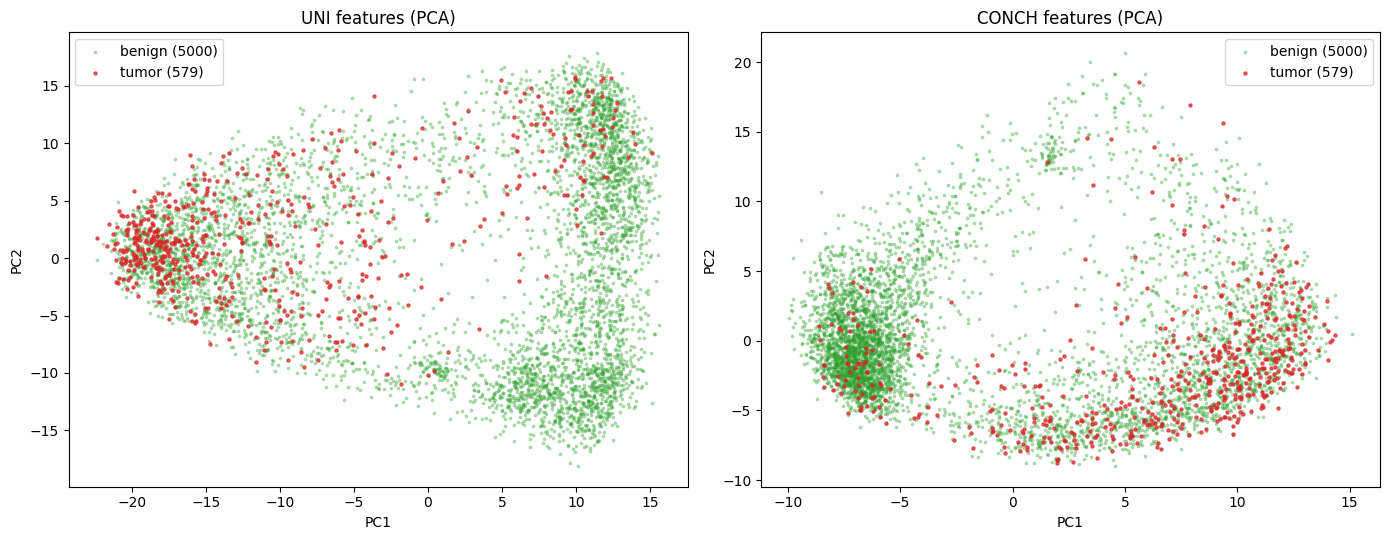

In [8]:
from sklearn.decomposition import PCA
fig, axes = plt.subplots(1, len(features), figsize=(7 * len(features), 5.5))
for ax, (name, X) in zip(np.atleast_1d(axes), features.items()):
    Z = PCA(n_components=2, random_state=SEED).fit_transform(X.astype(np.float32))
    b, tm = tiles.y.values == 0, tiles.y.values == 1
    ax.scatter(Z[b, 0], Z[b, 1], s=3, alpha=0.3, c='tab:green', label=f'benign ({b.sum()})')
    ax.scatter(Z[tm, 0], Z[tm, 1], s=5, alpha=0.7, c='tab:red', label=f'tumor ({tm.sum()})')
    ax.set_title(f'{name} features (PCA)'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend()
plt.tight_layout(); save_fig('pca'); plt.show()

## 5. Linear probe with spatial cross-validation
A logistic regression on top of each encoder's features. Neighbouring tiles look alike, so random splits would leak:
the slide is cut into blocks of about 2 mm, and each fold tests on blocks it never trained on.
Scores are out-of-fold predictions, pooled over the 5 folds.

In [9]:
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, average_precision_score

y, groups = tiles.y.values, tiles.block.values
n_folds = min(5, len(np.unique(groups)))
print(f'{n_folds} folds over {len(np.unique(groups))} spatial blocks; tumor appears in {tiles[tiles.y == 1].block.nunique()} blocks')
oof, rows = {}, []
for name, X in features.items():
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight='balanced', max_iter=3000))
    p = cross_val_predict(clf, X.astype(np.float32), y, groups=groups, cv=GroupKFold(n_splits=n_folds), method='predict_proba')[:, 1]
    oof[name] = p
    rows.append({'model': f'{name} linear probe', 'AUC': roc_auc_score(y, p),
                 'balanced_acc': balanced_accuracy_score(y, p > 0.5), 'avg_precision': average_precision_score(y, p)})

5 folds over 138 spatial blocks; tumor appears in 10 blocks


## 6. CONCH zero-shot (no training)
Each tile is compared with text descriptions of cancer and of benign tissue; the score is how much closer it is to the cancer texts.

In [11]:
from conch.open_clip_custom import get_tokenizer

def conch_tokenize(tokenizer, texts):
    # same as CONCH's tokenize(), written for the current transformers version
    t = tokenizer(texts, max_length=127, add_special_tokens=True, return_token_type_ids=False,
                  truncation=True, padding='max_length', return_tensors='pt')
    return F.pad(t['input_ids'], (0, 1), value=tokenizer.pad_token_id)

PROMPTS = {
    'tumor':  ['prostate adenocarcinoma', 'an H&E image of prostate adenocarcinoma',
               'invasive carcinoma of the prostate', 'Gleason pattern 4 prostate cancer'],
    'benign': ['benign prostatic tissue', 'an H&E image of normal prostate',
               'benign prostatic glands and stroma', 'prostate stroma'],
}
with torch.no_grad():
    tok = get_tokenizer()
    cls = []
    for k in ['benign', 'tumor']:
        e = conch_model.encode_text(conch_tokenize(tok, PROMPTS[k]).to(DEVICE)).float()
        cls.append(F.normalize(F.normalize(e, dim=-1).mean(0), dim=-1))
    text = torch.stack(cls).cpu().numpy()
sims = conch_proj @ text.T
zs = sims[:, 1] - sims[:, 0]
oof['CONCH zero-shot'] = zs
rows.append({'model': 'CONCH zero-shot', 'AUC': roc_auc_score(y, zs),
             'balanced_acc': balanced_accuracy_score(y, zs > 0), 'avg_precision': average_precision_score(y, zs)})

results = pd.DataFrame(rows).set_index('model').round(3)
results['tumor share (chance avg_precision)'] = round(y.mean(), 3)
display(results)
results.to_csv(os.path.join(OUT_DIR, 'results.csv'))

,AUC,balanced_acc,avg_precision,tumor share (chance avg_precision)
model,,,,
UNI linear probe,0.917,0.797,0.655,0.104
CONCH linear probe,0.874,0.787,0.526,0.104
CONCH zero-shot,0.731,0.636,0.267,0.104


## 7. Predictions on the slide
Each square is one tile. Left: our labels. Others: predicted tumor score (out-of-fold for the probes).
Unsampled benign tiles are blank.

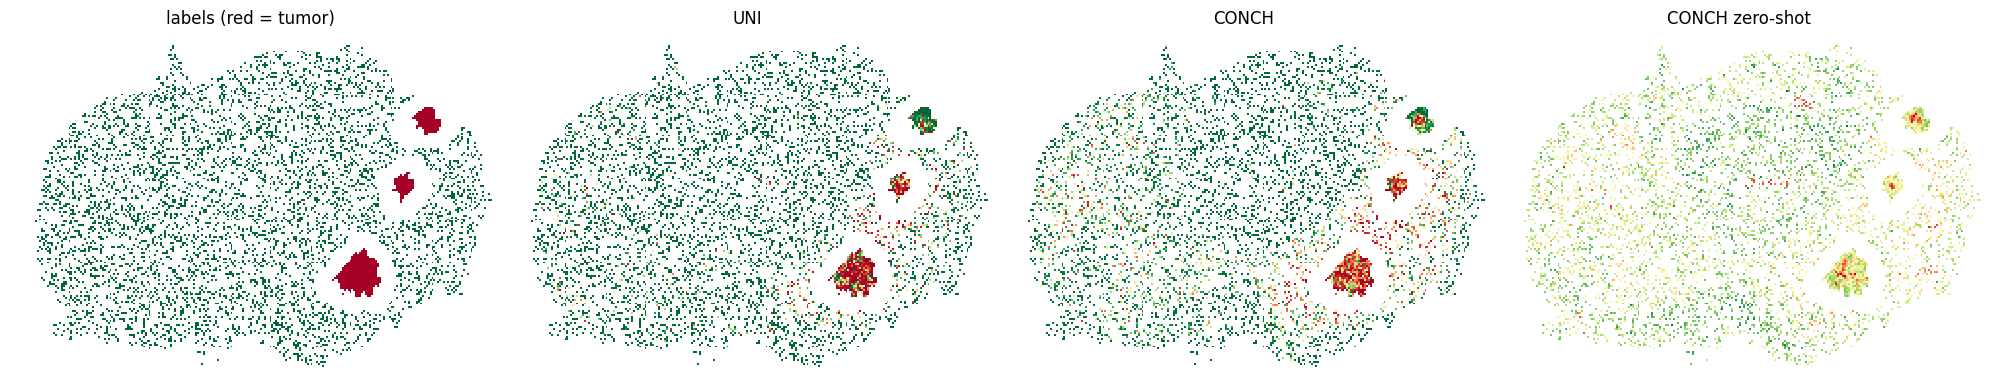

In [12]:
H, W = tiles.gy.max() + 1, tiles.gx.max() + 1
panels = [('labels (red = tumor)', tiles.y.values.astype(float))] + [(k, v) for k, v in oof.items()]
fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 5))
for ax, (name, v) in zip(axes, panels):
    g = np.full((H, W), np.nan)
    vv = v if name.startswith('labels') else (v - np.nanmin(v)) / (np.nanmax(v) - np.nanmin(v) + 1e-9)
    g[tiles.gy, tiles.gx] = vv
    ax.imshow(g, cmap='RdYlGn_r', vmin=0, vmax=1, interpolation='nearest')
    ax.set_title(name); ax.axis('off')
plt.tight_layout(); save_fig('prediction_maps'); plt.show()

## 8. Top-scoring tiles
The 8 tiles each model is most sure are tumor, and the 8 benign-labeled tiles it scores highest (possible label noise or real mistakes).

In [13]:
reader = SlideReader(SLIDE)
for name, v in oof.items():
    top_t = tiles.assign(s=v)[tiles.y == 1].nlargest(8, 's')
    top_b = tiles.assign(s=v)[tiles.y == 0].nlargest(8, 's')
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
    for r, g in enumerate([top_t, top_b]):
        for c in range(8):
            ax = axes[r, c]; ax.axis('off')
            if c < len(g):
                row = g.iloc[c]
                ax.imshow(reader.read_region(int(row.x0), int(row.y0), int(row.tile_px), int(row.tile_px)))
    axes[0, 0].set_title('labeled tumor, highest score', loc='left', fontsize=10)
    axes[1, 0].set_title('labeled benign, highest score', loc='left', fontsize=10)
    fig.suptitle(name); plt.tight_layout(); save_fig(f'top_tiles_{name.replace(" ", "_")}'); plt.show()
reader.close()

Output hidden; open in https://colab.research.google.com to view.